In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat, enumerate_ancestral_graphs, AncestralGraph
from agfx.special.linear_gaussian import sample_linear_gaussian
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet

In [2]:
num_nodes = 5
bs = 64
dmid = 64

iterations = int(1e4)
logr_t = LogRewardType.BIC
loss_t = LossType.CB

seed = 42

reward_seed = 43

In [3]:
all_graphs = enumerate_ancestral_graphs(num_nodes)

In [4]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
    reward_key, num_nodes, num_samples=600
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

In [5]:
def train_gfn(seed: int, logr_t: LogRewardType, **kwargs):
    key = jax.random.key(seed)
    k1, k2 = jax.random.split(key, 2)

    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)
    # Create the reward function
    logr = create_log_reward(logr_t, data, true_graph, **kwargs)

    gfn, _ = train(gfn, state, k1, logr, iterations, loss_t)
    return gfn, state

In [6]:
gfn, state = train_gfn(seed, LogRewardType.BIC)

100%|██████████| 10000/10000 [03:05<00:00, 53.99it/s, loss=1.14e+00]


## Human in the loop

In [7]:
from mpl_preamble import *

In [8]:
from agfx.eitl import QueryMethod, expert, next_query, EIPolicy
from agfx.policies import rollout_many
from agfx.evals import shd

In [9]:
def run(
    query_method: QueryMethod, 
    seed: int, 
    gfn: GFlowNet, 
    state: AncestralGraph, 
    n: int = 40, 
    beta_rate: float = 5e-2,
    pi: float = .5, 
    pi_star: float = .5,
):
    key = jax.random.key(seed) 
    ei_policy = EIPolicy(num_nodes, pi=pi)

    ei_policy.set_config(ei_policy.config.replace(beta_rate=beta_rate))

    shds = [] 

    for _ in range(n):
        rel, key = next_query(ei_policy, method=query_method, key=key)
        ans, key = expert(true_graph, pi=pi_star, rel=rel, key=key)
        ei_policy.update(rel, ans)

        samples = rollout_many(gfn, state, key, num_rollouts=20, fpol=ei_policy)
        # log_scores = jax.vmap(lambda s: ei_policy.log_score(s, logr), in_axes=(0,), out_axes=0)(samples)

        v = jax.vmap(shd, in_axes=(0, None), out_axes=0)(samples, true_graph)
        shds.append(v.mean())
    
    return shds

In [10]:
results_per_pi = {}

pis = [.6, .9, .9]
pi_stars = [.9, .9, .6]

seeds = [42, 84, 126]
beta_rate = .9

for (pi, pi_star) in zip(pis, pi_stars):
    shds_linear = [] 
    shds_const = [] 

    for seed in seeds:
        shds_linear.append(run(
            QueryMethod.ENTROPY, 
            seed=seed, gfn=gfn, 
            state=state, 
            beta_rate=beta_rate, 
            pi=pi, 
            pi_star=pi_star,
        ))
        shds_const.append(run(
            QueryMethod.ENTROPY, 
            seed=seed, gfn=gfn, 
            state=state, 
            beta_rate=1,
            pi=pi,
            pi_star=pi_star,
        )) 
    
    results_per_pi[(pi, pi_star)] = (shds_linear, shds_const)

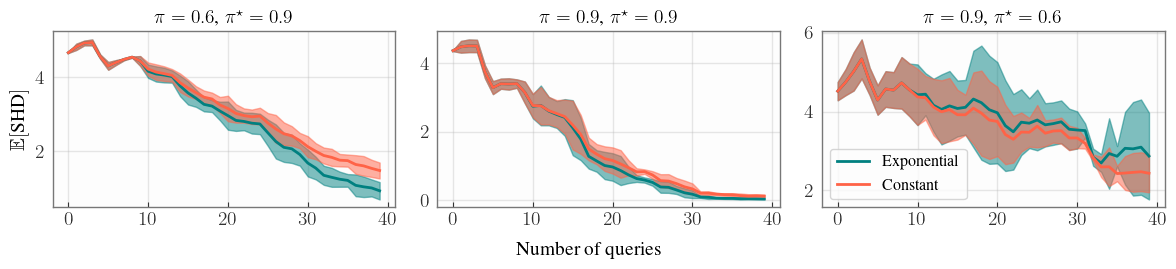

In [ ]:
fig = plt.figure(figsize=(12, 3))

def plot(v: list, label: str, c: str = None):
    v = jnp.array(v) 
    m = v.mean(axis=0) 
    s = v.std(axis=0) 
    i = jnp.arange(len(m)) 

    plt.plot(i, m, label=label, c=c)
    plt.fill_between(i, m-s, m+s, alpha=.5, color=c)
    

i = 1 

for (pi, pi_star) in results_per_pi:

    ax = plt.subplot(1, 3, i) 

    shds_linear, shds_const = results_per_pi[(pi, pi_star)]

    plot(shds_linear, label="Exponential", c="teal")
    plot(shds_const, label="Constant", c="tomato")

    ax.set_title(f"$\\pi = {pi}$, $\\pi^{{\\star}} = {pi_star}$") 


    if i == 1:
        plt.ylabel("$\\mathbb{E}[\\text{SHD}]$")


    i = i + 1

fig.supxlabel("Number of queries", size=14, y=.1)

plt.legend()
plt.tight_layout() 

plt.savefig("figures/eitl_schedules.pdf")